#Paquetes necesarios

In [37]:
import cv2
import math
import numpy as np
from collections import Counter, defaultdict
from ultralytics import YOLO

In [38]:
# Carga del modelo
model = YOLO('yolo26s.pt')

#Para un vídeo
filename = "C0142.MP4"

clase_persona = 0 # Persona
clases_vehiculos = {1, 2, 3, 5, 7} # bicicleta, coche, moto, guagua, camión
nombres = {0: "persona", 1: "bicicleta", 2: "coche", 3: "moto", 5: "guagua", 7: "camion"}

# con botsort.yaml salían muchísimos más ids, el tracker que viene por defecto va mejor con este vídeo
results = model.track(source=filename, show=True, stream=True, persist=True, verbose=False,
                      classes=[clase_persona, *clases_vehiculos])

# Al principio contaba casi 60 cosas porque a los coches aparcados les cambia el id cada dos por tres,
# así que solo cuento lo que aparece un rato y además se mueve
MIN_FRAMES = 15            # fotogramas mínimos que tiene que salir
MIN_DESPL_VEHICULO = 0.10  # lo que se tiene que mover, en proporción al ancho del vídeo
MIN_DESPL_PERSONA = 0.05   # las personas van más despacio, les pido menos

historial = defaultdict(list) # id -> lista de (clase, x del centro, y del centro), uno por fotograma

for r in results:
    ancho = r.orig_shape[1]
    if r.boxes.id is None:
        continue

    id = r.boxes.id.int().cpu().tolist()
    clase = r.boxes.cls.int().cpu().tolist()
    cajas = r.boxes.xyxy.cpu().tolist()

    for track_id, class_id, (x1, y1, x2, y2) in zip(id, clase, cajas):
        historial[track_id].append((class_id, (x1 + x2) / 2, (y1 + y2) / 2))

cv2.destroyAllWindows()


def clase_mayoritaria(puntos):
    # a veces un coche sale como camión en algún fotograma, así que me quedo con la que más se repite
    clases = [c for c, x, y in puntos]
    return Counter(clases).most_common(1)[0][0]


def cuanto_se_mueve(puntos):
    # distancia entre donde empieza y donde acaba
    # (hago la media de los 5 primeros y los 5 últimos centros porque la caja tiembla un poco)
    centros = np.array([(x, y) for c, x, y in puntos])
    inicio = centros[:5].mean(axis=0)
    final = centros[-5:].mean(axis=0)
    return np.linalg.norm(final - inicio)


def se_cuenta(puntos):
    if clase_mayoritaria(puntos) == clase_persona:
        minimo = MIN_DESPL_PERSONA * ancho
    else:
        minimo = MIN_DESPL_VEHICULO * ancho
    return len(puntos) >= MIN_FRAMES and cuanto_se_mueve(puntos) >= minimo


ids_personas = set()
ids_vehiculos = set()
conteo = Counter()

for track_id, puntos in historial.items():
    if not se_cuenta(puntos):
        continue
    class_id = clase_mayoritaria(puntos)
    if class_id == clase_persona:
        ids_personas.add(track_id)
    else:
        ids_vehiculos.add(track_id)
    conteo[nombres[class_id]] += 1

print("IDs distintos sin filtrar:", len(historial))
print("PERSONAS: ",sorted(ids_personas))
print("VEHICULOS: ", sorted(ids_vehiculos))

print("Total PERSONAS: ",len(ids_personas))
print("Total VEHICULOS: ",len(ids_vehiculos))
print("Por clase:", dict(conteo))

IDs distintos sin filtrar: 94
PERSONAS:  [4, 8, 9, 12, 24, 25, 33, 40, 44, 46, 51, 57, 72, 77, 82, 83, 85, 96]
VEHICULOS:  [1, 10, 11, 13, 15, 17, 20, 22, 26, 27, 30, 34, 37, 41, 43, 45, 49, 52, 56, 62, 74, 75, 76, 78, 80, 88, 90, 92, 94, 95, 101, 103]
Total PERSONAS:  18
Total VEHICULOS:  32
Por clase: {'guagua': 1, 'persona': 18, 'coche': 27, 'moto': 3, 'bicicleta': 1}


In [39]:
# Cargar tu modelo entrenado
model = YOLO("best.pt")

# Seguimiento de matrículas
results = model.track(
    source=filename,
    conf=0.3,
    imgsz=1920,
    show=True,
    show_conf=False,
    stream=True,
    persist=True,
    verbose=False,
)

# lo mismo que con los coches: si no, cuenta también las matrículas de los aparcados
MIN_FRAMES_MATRICULA = 10
MIN_DESPL_MATRICULA = 0.05

historial_mat = defaultdict(list) # id -> lista de centros (x, y)

for r in results:
    ancho = r.orig_shape[1]
    if r.boxes.id is not None:
        ids = r.boxes.id.int().cpu().tolist()
        cajas = r.boxes.xyxy.cpu().tolist()
        for track_id, (x1, y1, x2, y2) in zip(ids, cajas):
            historial_mat[track_id].append(((x1 + x2) / 2, (y1 + y2) / 2))

cv2.destroyAllWindows()

# Contar matrículas diferentes
ids_matriculas = set()

for track_id, centros in historial_mat.items():
    centros = np.array(centros)
    movimiento = np.linalg.norm(centros[-5:].mean(axis=0) - centros[:5].mean(axis=0))
    if len(centros) >= MIN_FRAMES_MATRICULA and movimiento >= MIN_DESPL_MATRICULA * ancho:
        ids_matriculas.add(track_id)

print("IDs sin filtrar:", len(historial_mat))
print("IDs de matrículas:", sorted(ids_matriculas))
print("TOTAL DE MATRÍCULAS:", len(ids_matriculas))

IDs sin filtrar: 33
IDs de matrículas: [2, 11, 26, 27, 32, 39, 53, 60, 74, 76, 83, 89, 97, 110, 112, 113, 121, 130, 140, 148, 155, 156, 158, 168, 169, 170, 171, 178, 179]
TOTAL DE MATRÍCULAS: 29


TRAIN

DATASET

In [40]:
import json
import random
import shutil
from pathlib import Path

# --- Configuración (corregida) ---
BASE             = Path.cwd()
IMAGES_DIR       = BASE / "dataset_2" / "images"
ANNOTATIONS_DIR  = BASE / "dataset_2" / "annotations"
DATASET_DIR      = BASE / "dataset"                  # destino con train/val/test

TRAIN_RATIO = 0.70
VAL_RATIO   = 0.20
TEST_RATIO  = 0.10

random.seed(42)

# --- Listar imágenes ---
image_extensions = {".jpg", ".jpeg", ".png"}
images = [p for p in IMAGES_DIR.iterdir() if p.suffix.lower() in image_extensions]
random.shuffle(images)

# --- Reparto ---
total     = len(images)
train_end = int(total * TRAIN_RATIO)
val_end   = train_end + int(total * VAL_RATIO)

splits = {
    "train": images[:train_end],
    "val":   images[train_end:val_end],
    "test":  images[val_end:],
}

# --- Crear estructura de carpetas destino (esto faltaba) ---
for split in splits:
    (DATASET_DIR / split / "images").mkdir(parents=True, exist_ok=True)
    (DATASET_DIR / split / "labels").mkdir(parents=True, exist_ok=True)

# --- Procesar ---
for split, split_images in splits.items():
    for image_path in split_images:
        json_path = ANNOTATIONS_DIR / (image_path.stem + ".json")
        if not json_path.exists():
            print(f"Falta anotación: {json_path}")
            continue

        with open(json_path, "r", encoding="utf-8") as f:
            annotations = json.load(f)

        # Copiar imagen
        destination_image = DATASET_DIR / split / "images" / image_path.name
        shutil.copy2(image_path, destination_image)

        # Crear txt YOLO
        destination_label = DATASET_DIR / split / "labels" / (image_path.stem + ".txt")
        with open(destination_label, "w", encoding="utf-8") as f:
            for annotation in annotations:
                x_center, y_center, width, height = annotation["rectangle"]
                f.write(f"0 {x_center} {y_center} {width} {height}\n")

print("Dataset preparado correctamente.")
for split, imgs in splits.items():
    print(f"{split}: {len(imgs)} imágenes")

# dataset.yaml apuntando a las carpetas creadas
with open("dataset.yaml", "w", encoding="utf-8") as f:
    f.write("path: dataset\ntrain: train/images\nval: val/images\ntest: test/images\nnames:\n  0: matricula\n")


Dataset preparado correctamente.
train: 1647 imágenes
val: 470 imágenes
test: 237 imágenes


In [41]:
# Cargar modelo YOLO26 preentrenado
#model = YOLO("yolo26s.pt")

# Entrenar para detectar matrículas
#results = model.train(
#    data="dataset.yaml",
#    epochs=100,
#    imgsz=1920,
#    batch=8,
#    optimizer="AdamW",
#    lr0=0.002,
#    name="detector_matriculas"
#)

#print("¡Entrenamiento finalizado!")

ANÁLISIS DEL ENTRENAMIENTO

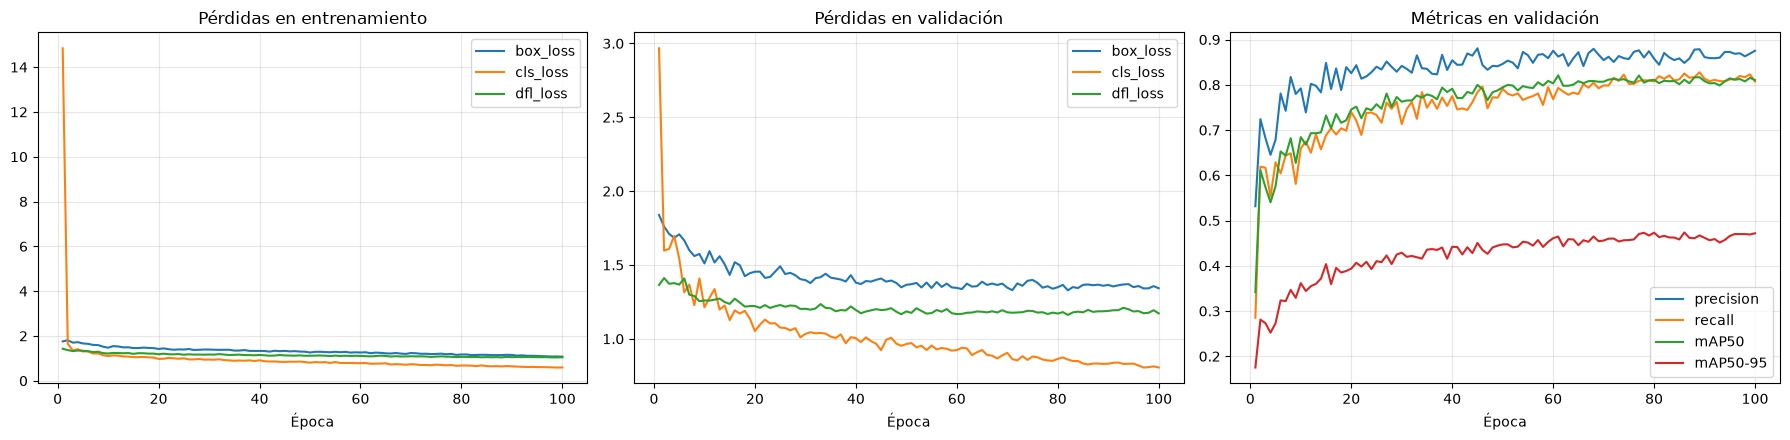

Mejor época: 86  P=0.848  R=0.825  mAP50=0.811  mAP50-95=0.474


In [42]:
import pandas as pd
import matplotlib.pyplot as plt

# carpeta del entrenamiento del que sale best.pt, ahí está el results.csv con todas las épocas
RUN_DIR = Path("detector_matriculas-3")
SALIDA = Path("resultados") # aquí guardo las gráficas
SALIDA.mkdir(exist_ok=True)

res = pd.read_csv(RUN_DIR / "results.csv")
res.columns = res.columns.str.strip() # las columnas vienen con espacios

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# pérdidas de entrenamiento y de validación (si la de validación sube mientras la otra baja, hay sobreajuste)
for perdida in ["box_loss", "cls_loss", "dfl_loss"]:
    axes[0].plot(res["epoch"], res["train/" + perdida], label=perdida)
    axes[1].plot(res["epoch"], res["val/" + perdida], label=perdida)
axes[0].set_title("Pérdidas en entrenamiento")
axes[1].set_title("Pérdidas en validación")

# métricas en validación
for metrica in ["precision", "recall", "mAP50", "mAP50-95"]:
    axes[2].plot(res["epoch"], res["metrics/" + metrica + "(B)"], label=metrica)
axes[2].set_title("Métricas en validación")

for ax in axes:
    ax.set_xlabel("Época")
    ax.grid(alpha=.3)
    ax.legend()
plt.tight_layout()
plt.savefig(SALIDA / "entrenamiento.png", dpi=120)
plt.show()

# la mejor época es la de mayor mAP50-95 (la que usa yolo para guardar best.pt)
mejor = res.loc[res["metrics/mAP50-95(B)"].idxmax()]
print(f"Mejor época: {int(mejor['epoch'])}  P={mejor['metrics/precision(B)']:.3f}  R={mejor['metrics/recall(B)']:.3f}  "
      f"mAP50={mejor['metrics/mAP50(B)']:.3f}  mAP50-95={mejor['metrics/mAP50-95(B)']:.3f}")

TEST

In [43]:
# Cargar el mejor modelo del segundo entrenamiento
model = YOLO("best.pt")

# métricas en test (con conf 0.35 sale una matriz de confusión que tiene sentido,
# con conf muy baja salían miles de falsos positivos)
metrics = model.val(
    data="dataset.yaml",
    split="test",
    imgsz=1920,
    batch=4,
    conf=0.35,
    plots=True
)
print(f"mAP50={metrics.box.map50:.3f}  mAP50-95={metrics.box.map:.3f}")

# Probar con las fotografías de test (se guardan con las cajas pintadas en runs/detect)
results = model.predict(
    source="dataset/test/images",
    imgsz=1920,
    conf=0.3,
    save=True,
    stream=True,
    verbose=False
)
for r in results:
    pass # con stream hay que recorrerlo para que haga algo
print("Prueba finalizada")

Ultralytics 8.4.202  Python-3.14.3 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 3070 Laptop GPU, 8192MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.2±0.0 ms, read: 200.8±194.0 MB/s, size: 3120.5 KB)
val: Scanning C:\Users\pablo\Desktop\INFORMATICA\Apuntes_4\VC\P4\P4\dataset\test\labels... 237 images, 0 backgrounds, 8 corrupt: 100% ━━━━━━━━━━━━ 237/237 335.2it/s 0.7s0.1s
val: C:\Users\pablo\Desktop\INFORMATICA\Apuntes_4\VC\P4\P4\dataset\test\images\njhm-013.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [ 535.       1019.5        63.         23.5       119.510666 1026.34
   35.277245   10.799789]
val: C:\Users\pablo\Desktop\INFORMATICA\Apuntes_4\VC\P4\P4\dataset\test\images\njhm-016.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [543.       818.86945  105.        44.738846]
val: C:\Users\pablo\Desktop\INFORMATICA\Apuntes_4\VC\P4\P4\dataset\test\image

OCR

Para leer las matrículas pruebo dos cosas:
* **EasyOCR**: un OCR "de toda la vida".
* **SmolVLM-Instruct**: un modelo de visión y lenguaje (VLM) al que le pasas la imagen y le preguntas qué pone.

In [44]:
import re
import time
import platform
import torch
import easyocr
from PIL import Image
from transformers import AutoProcessor, AutoModelForImageTextToText

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    torch.cuda.empty_cache() # libera lo que haya dejado yolo en la gráfica

# EasyOCR
lector_easy = easyocr.Reader(["es"], gpu=DEVICE == "cuda")

# SmolVLM
VLM_ID = "HuggingFaceTB/SmolVLM-Instruct"
# do_image_splitting=False para que no trocee la imagen: la matrícula es pequeña y si no va lentísimo y se come la VRAM
vlm_proc = AutoProcessor.from_pretrained(VLM_ID, do_image_splitting=False)
if DEVICE == "cuda":
    tipo = torch.bfloat16 # en la gráfica a media precisión, cabe mejor
else:
    tipo = torch.float32
vlm = AutoModelForImageTextToText.from_pretrained(VLM_ID, dtype=tipo).to(DEVICE).eval()

pregunta = [{"role": "user", "content": [
    {"type": "image"},
    {"type": "text", "text": "Read the license plate. Answer only with its characters."},
]}]
VLM_PROMPT = vlm_proc.apply_chat_template(pregunta, add_generation_prompt=True)

# formato de matrícula española: la actual (1234ABC) y la antigua (GC1234AB)
PATRONES = [r"\d{4}[A-Z]{3}", r"[A-Z]{1,2}\d{4}[A-Z]{1,2}"]


def limpiar(texto):
    # paso a mayúsculas y quito todo lo que no sea letra o número
    texto = re.sub(r"[^A-Z0-9]", "", texto.upper())
    # si dentro hay algo con forma de matrícula me quedo solo con eso (así se va la "E" de la franja azul)
    for patron in PATRONES:
        encontrado = re.search(patron, texto)
        if encontrado:
            return encontrado.group(0)
    return texto


def es_valida(texto):
    for patron in PATRONES:
        if re.fullmatch(patron, texto):
            return True
    return False


def leer_easyocr(recorte):
    # allowlist para que solo pueda devolver letras mayúsculas y números
    trozos = lector_easy.readtext(recorte, detail=0, allowlist="ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789")
    return limpiar("".join(trozos))


def leer_smolvlm(recorte):
    imagen = Image.fromarray(cv2.cvtColor(recorte, cv2.COLOR_BGR2RGB)) # opencv va en BGR
    entrada = vlm_proc(text=VLM_PROMPT, images=[imagen], return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        salida = vlm.generate(**entrada, max_new_tokens=12, do_sample=False)
    respuesta = salida[:, entrada["input_ids"].shape[1]:] # quito la pregunta, me quedo con lo que contesta
    return limpiar(vlm_proc.batch_decode(respuesta, skip_special_tokens=True)[0])


OCRS = {"EasyOCR": leer_easyocr, "SmolVLM": leer_smolvlm}

Loading weights: 100%|██████████| 657/657 [00:04<00:00, 137.24it/s]


COMPARATIVA EASYOCR VS SMOLVLM

Los dos leen exactamente lo mismo: las matrículas de las fotos de **test** que tienen el texto apuntado en el JSON, recortadas con su caja.
Miro tres cosas:
* **Tasa de acierto**: cuántas lee enteras y bien.
* **Acierto por carácter**: para que una lectura con una sola letra mal no cuente igual que una que no se parece en nada.
* **Tiempo** que tarda en leer cada matrícula.

In [45]:
def distancia_edicion(a, b):
    # distancia de Levenshtein: cuántas letras hay que cambiar, quitar o poner para pasar de a a b
    tabla = [[0] * (len(b) + 1) for _ in range(len(a) + 1)]
    for i in range(len(a) + 1):
        tabla[i][0] = i
    for j in range(len(b) + 1):
        tabla[0][j] = j
    for i in range(1, len(a) + 1):
        for j in range(1, len(b) + 1):
            if a[i - 1] == b[j - 1]:
                coste = 0
            else:
                coste = 1
            tabla[i][j] = min(tabla[i - 1][j] + 1, tabla[i][j - 1] + 1, tabla[i - 1][j - 1] + coste)
    return tabla[len(a)][len(b)]


# Recorto las matrículas de las fotos de test junto con el texto que pone de verdad
muestras = [] # (nombre de la foto, texto real, recorte)
for img_path in splits["test"]:
    with open(ANNOTATIONS_DIR / (img_path.stem + ".json"), encoding="utf-8") as f:
        anotaciones = json.load(f)
    img = cv2.imread(str(img_path))
    H, W = img.shape[:2]

    for a in anotaciones:
        real = re.sub(r"[^A-Z0-9]", "", str(a.get("plate")).upper())
        if not es_valida(real):
            continue # hay muchas sin texto apuntado ("None")

        cx, cy, w, h = map(float, a["rectangle"])
        if max(cx, cy, w, h) > 1.5:
            # algunas fotos (njhm-*) tienen la caja en píxeles en vez de normalizada, y el tamaño
            # que vale es el de la foto ya girada (opencv ya la gira al leerla)
            cx, cy, w, h = cx / W, cy / H, w / W, h / H
        x1, y1 = int((cx - w / 2) * W), int((cy - h / 2) * H)
        x2, y2 = int((cx + w / 2) * W), int((cy + h / 2) * H)
        if x2 - x1 >= 10 and y2 - y1 >= 5: # las diminutas no hay quien las lea
            muestras.append((img_path.name, real, img[y1:y2, x1:x2]))
print("Matrículas para la comparativa:", len(muestras))


def esperar_gpu():
    # la gpu va por su cuenta, si no espero a que acabe el tiempo medido no es real
    if DEVICE == "cuda":
        torch.cuda.synchronize()


# la primera lectura en gpu siempre tarda más, así que hago una de calentamiento que no cuenta
for leer in OCRS.values():
    leer(muestras[0][2])

filas = []
for nombre, leer in OCRS.items():
    for archivo, real, recorte in muestras:
        esperar_gpu()
        inicio = time.perf_counter()
        leido = leer(recorte)
        esperar_gpu()
        tiempo = (time.perf_counter() - inicio) * 1000

        filas.append({"modelo": nombre, "imagen": archivo, "real": real, "leido": leido,
                      "acierto": leido == real,
                      "acierto_caracter": max(0.0, 1 - distancia_edicion(leido, real) / len(real)),
                      "tiempo_ms": tiempo})
    print(f"{nombre}: {len(muestras)} matrículas leídas")

comparativa = pd.DataFrame(filas)
comparativa.to_csv(SALIDA / "ocr_comparativa.csv", index=False)

resumen_ocr = comparativa.groupby("modelo").agg(
    tasa_acierto=("acierto", "mean"),
    acierto_caracter=("acierto_caracter", "mean"),
    tiempo_medio_ms=("tiempo_ms", "mean"),
    tiempo_mediana_ms=("tiempo_ms", "median"))
print(resumen_ocr.round(3))

# Especificaciones del portátil (las pide el enunciado)
print("\nEquipo:", platform.processor(), "|", platform.system(), platform.release())
if DEVICE == "cuda":
    gpu = torch.cuda.get_device_name(0)
else:
    gpu = "ninguna"
print("GPU:", gpu, "| Python", platform.python_version(), "| torch", torch.__version__)

Matrículas para la comparativa: 319
EasyOCR: 319 matrículas leídas
SmolVLM: 319 matrículas leídas
         tasa_acierto  acierto_caracter  tiempo_medio_ms  tiempo_mediana_ms
modelo                                                                     
EasyOCR         0.420             0.650          155.159             76.504
SmolVLM         0.799             0.926         2643.606           2639.103

Equipo: Intel64 Family 6 Model 165 Stepping 2, GenuineIntel | Windows 11
GPU: NVIDIA GeForce RTX 3070 Laptop GPU | Python 3.14.3 | torch 2.15.0+cu132


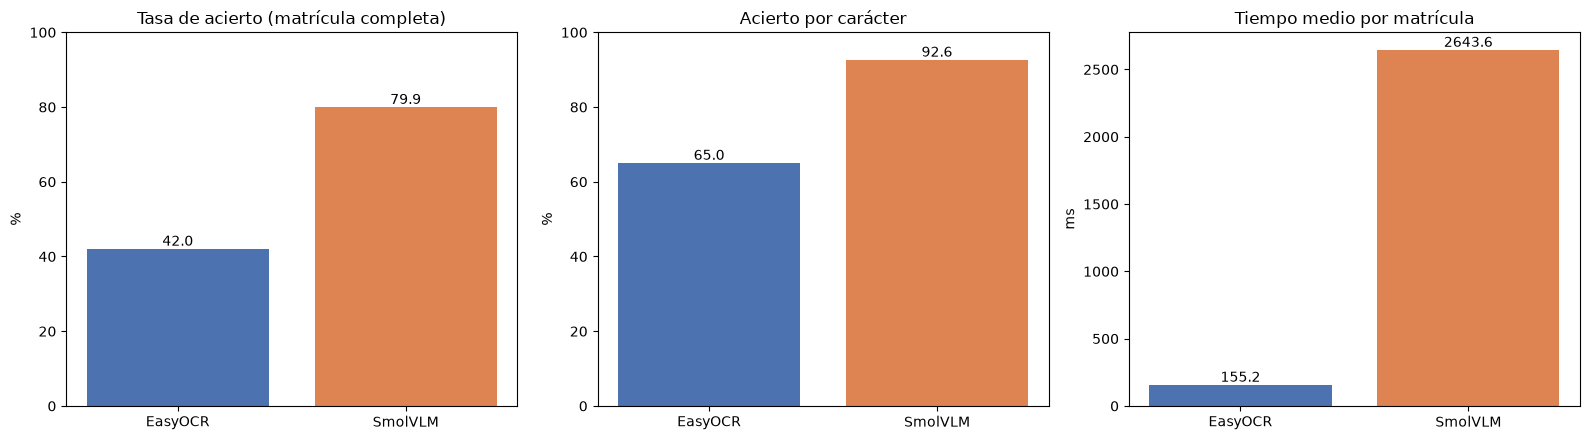

 modelo     real   leido
EasyOCR  4235MMZ VMZ4235
EasyOCR  8772GTT  8772GT
EasyOCR  7761LSJ      TU
EasyOCR  9661KYV    7966
EasyOCR  1499MJS     IES
SmolVLM GC0649BY GC069BY
SmolVLM  9661KYV 9661KVR
SmolVLM  1499MJS 1699MJS
SmolVLM  1137MDN 1137MON
SmolVLM  5174JYF  517JYF


In [46]:
# Gráficas de la comparativa
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
colores = ["#4C72B0", "#DD8452"]

axes[0].bar(resumen_ocr.index, resumen_ocr["tasa_acierto"] * 100, color=colores)
axes[0].set_title("Tasa de acierto (matrícula completa)")
axes[0].set_ylabel("%")
axes[0].set_ylim(0, 100)

axes[1].bar(resumen_ocr.index, resumen_ocr["acierto_caracter"] * 100, color=colores)
axes[1].set_title("Acierto por carácter")
axes[1].set_ylabel("%")
axes[1].set_ylim(0, 100)

axes[2].bar(resumen_ocr.index, resumen_ocr["tiempo_medio_ms"], color=colores)
axes[2].set_title("Tiempo medio por matrícula")
axes[2].set_ylabel("ms")

# el número encima de cada barra
for ax in axes:
    for barra in ax.patches:
        x = barra.get_x() + barra.get_width() / 2
        ax.annotate(f"{barra.get_height():.1f}", (x, barra.get_height()), ha="center", va="bottom")

plt.tight_layout()
plt.savefig(SALIDA / "ocr_comparativa.png", dpi=120)
plt.show()

# unos cuantos ejemplos en los que falla cada uno
fallos = comparativa[comparativa["acierto"] == False]
print(fallos.groupby("modelo").head(5)[["modelo", "real", "leido"]].to_string(index=False))

PROTOTIPO

Lo junto todo para sacar el vídeo y el CSV:
1. Sigo personas y vehículos con `yolo26s.pt` y dentro de cada vehículo busco la matrícula con `best.pt`.
2. De cada vehículo me guardo los recortes de matrícula más nítidos, los leo con el OCR y me quedo con lo que más se repite.
3. Cuento igual que arriba.
4. Saco `resultado.mp4` y `resultado.csv`.

In [47]:
OCR_PROTOTIPO = "SmolVLM"   # o "EasyOCR", que va más rápido pero acierta menos
RECORTES_POR_VEHICULO = 5   # cuántas fotos de la matrícula leo por cada vehículo
VIDEO_SALIDA = "resultado.mp4"
CSV_SALIDA = "resultado.csv"

model = YOLO("yolo26s.pt")
model_mat = YOLO("best.pt")

results = model.track(source=filename, show=False, stream=True, persist=True, verbose=False,
                      classes=[clase_persona, *clases_vehiculos])

detecciones = []                      # una fila por objeto y fotograma, de aquí sale el CSV
historial = defaultdict(list)         # id -> lista de (clase, x del centro, y del centro)
mejores_recortes = defaultdict(list)  # id -> lista de (nitidez, recorte de la matrícula)


def nitidez(recorte):
    # varianza del laplaciano: cuanto más alta, menos movida está la foto
    # (la paso a 160 de ancho para poder comparar recortes de distinto tamaño)
    alto = max(1, int(160 * recorte.shape[0] / recorte.shape[1]))
    gris = cv2.cvtColor(cv2.resize(recorte, (160, alto)), cv2.COLOR_BGR2GRAY)
    return cv2.Laplacian(gris, cv2.CV_64F).var()


for n_frame, r in enumerate(results):
    frame = r.orig_img
    ancho = frame.shape[1]
    if r.boxes.id is None:
        continue

    ids = r.boxes.id.int().cpu().tolist()
    clases = r.boxes.cls.int().cpu().tolist()
    confs = r.boxes.conf.cpu().tolist()
    cajas = r.boxes.xyxy.cpu().tolist()

    for track_id, class_id, conf, caja in zip(ids, clases, confs, cajas):
        x1, y1, x2, y2 = [int(v) for v in caja]
        historial[track_id].append((class_id, (x1 + x2) / 2, (y1 + y2) / 2))
        fila = {"fotograma": n_frame, "identificador_tracking": track_id, "clase": class_id,
                "confianza": round(conf, 3), "x1": x1, "y1": y1, "x2": x2, "y2": y2,
                "mat": None} # si encuentra matrícula: (confianza, mx1, my1, mx2, my2)

        # busco la matrícula dentro del vehículo (las bicis no tienen y si el coche está muy lejos no merece la pena)
        if class_id in clases_vehiculos and class_id != 1 and y2 - y1 >= 60:
            rm = model_mat.predict(frame[y1:y2, x1:x2], imgsz=640, conf=0.3, verbose=False)[0]
            if len(rm.boxes) > 0:
                i = int(rm.boxes.conf.argmax()) # si hay varias, la más segura
                mx1, my1, mx2, my2 = [int(v) for v in rm.boxes.xyxy[i].tolist()]
                # las coordenadas son del recorte, les sumo la esquina del coche para pasarlas al fotograma
                mx1, my1, mx2, my2 = mx1 + x1, my1 + y1, mx2 + x1, my2 + y1
                fila["mat"] = (round(float(rm.boxes.conf[i]), 3), mx1, my1, mx2, my2)

                recorte = frame[my1:my2, mx1:mx2]
                if recorte.shape[1] >= 30: # con menos de 30 píxeles de ancho no se lee nada
                    # me quedo solo con los más nítidos (los más grandes suelen salir movidos)
                    mejores_recortes[track_id].append((nitidez(recorte), recorte.copy()))
                    mejores_recortes[track_id].sort(key=lambda t: t[0], reverse=True)
                    mejores_recortes[track_id] = mejores_recortes[track_id][:RECORTES_POR_VEHICULO]
        detecciones.append(fila)

print("Fotogramas procesados:", n_frame + 1, "| tracks:", len(historial))

Fotogramas procesados: 2832 | tracks: 94


In [48]:
# El OCR muchas veces confunde letras y números que se parecen (S/5, B/8, G/6...).
# Como la matrícula nueva es siempre 4 números + 3 letras, lo arreglo según la posición
A_NUMERO = {"O": "0", "D": "0", "Q": "0", "I": "1", "L": "1", "Z": "2", "S": "5", "G": "6", "T": "7", "B": "8"}
A_LETRA = {"0": "D", "2": "Z", "5": "S", "6": "G", "8": "B"}


def corregir_formato(texto):
    # ej: "S143LCY" -> "5143LCY",  "7339L66" -> "7339LGG"
    if es_valida(texto):
        return texto # si ya está bien no la toco
    if len(texto) == 8:
        texto = texto[1:] # le sobra uno delante (la "E" de la franja azul)
    if len(texto) != 7:
        return texto
    numeros = "".join(A_NUMERO.get(c, c) for c in texto[:4])
    letras = "".join(A_LETRA.get(c, c) for c in texto[4:])
    if es_valida(numeros + letras):
        return numeros + letras
    return texto


# Leo los recortes de cada vehículo y me quedo con la lectura que más se repite
leer = OCRS[OCR_PROTOTIPO]
texto_matricula = {} # id -> texto de la matrícula
for track_id, recortes in mejores_recortes.items():
    validas = []
    for nit, recorte in recortes:
        texto = corregir_formato(leer(recorte))
        if es_valida(texto):
            validas.append(texto)
    if validas:
        texto_matricula[track_id] = Counter(validas).most_common(1)[0][0]
print("Vehículos con matrícula leída:", len(texto_matricula))


# Cuento con los mismos filtros de arriba (se_cuenta)
clase_track = {} # id -> clase
contados = set() # ids de los que cuentan
for track_id, puntos in historial.items():
    clase_track[track_id] = clase_mayoritaria(puntos)
    if se_cuenta(puntos):
        contados.add(track_id)

conteo = Counter(nombres[clase_track[t]] for t in contados)
print("Total PERSONAS:", conteo["persona"])
print("Total VEHICULOS:", sum(v for k, v in conteo.items() if k != "persona"))
print("Por clase:", dict(conteo))


Vehículos con matrícula leída: 22
Total PERSONAS: 18
Total VEHICULOS: 32
Por clase: {'guagua': 1, 'persona': 18, 'coche': 27, 'moto': 3, 'bicicleta': 1}


In [49]:
# CSV con los campos que pide el enunciado
# solo meto lo que se ha contado (nada de coches aparcados ni detecciones sueltas)
# el texto de la matrícula va en todas las filas del vehículo, las coordenadas solo cuando se ve en ese fotograma
filas_csv = []
for d in detecciones:
    tid = d["identificador_tracking"]
    if tid not in contados:
        continue

    if d["mat"] is not None:
        conf_mat, mx1, my1, mx2, my2 = d["mat"]
        hay_matricula = 1
    else:
        conf_mat, mx1, my1, mx2, my2 = "", "", "", "", ""
        hay_matricula = 0

    filas_csv.append({
        "fotograma": d["fotograma"],
        "tipo_objeto": nombres[clase_track[tid]],
        "confianza": d["confianza"],
        "identificador_tracking": tid,
        "x1": d["x1"], "y1": d["y1"], "x2": d["x2"], "y2": d["y2"],
        "matricula_en_su_caso": hay_matricula,
        "confianza_matricula": conf_mat,
        "mx1": mx1, "my1": my1, "mx2": mx2, "my2": my2,
        "texto_matricula": texto_matricula.get(tid, ""),
    })
pd.DataFrame(filas_csv).to_csv(CSV_SALIDA, index=False)
print("CSV guardado:", CSV_SALIDA, "-", len(filas_csv), "filas")

# Vídeo de salida: vuelvo a leer el vídeo y pinto encima lo que ya tengo calculado
por_fotograma = defaultdict(list) # fotograma -> detecciones de ese fotograma
for d in detecciones:
    if d["identificador_tracking"] in contados: # igual que en el CSV, solo lo que se cuenta
        por_fotograma[d["fotograma"]].append(d)

cap = cv2.VideoCapture(filename)
fps = cap.get(cv2.CAP_PROP_FPS)
W = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
H = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
writer = cv2.VideoWriter(VIDEO_SALIDA, cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))


def etiqueta(img, texto, x, y, fondo, color_texto=(255, 255, 255), escala=0.45):
    # texto pequeñito con un rectángulo de fondo para que se lea bien (con letra grande tapaba todo)
    (tw, th), base = cv2.getTextSize(texto, cv2.FONT_HERSHEY_SIMPLEX, escala, 1)
    x = max(0, x)
    y = max(th + 4, y) # que no se salga por arriba
    cv2.rectangle(img, (x, y - th - 4), (x + tw + 4, y + base - 2), fondo, -1)
    cv2.putText(img, texto, (x + 2, y - 3), cv2.FONT_HERSHEY_SIMPLEX, escala, color_texto, 1, cv2.LINE_AA)


vistos = set() # para el contador de arriba: los que ya han salido hasta ahora
n_frame = 0
while True:
    ok, frame = cap.read()
    if not ok:
        break

    for d in por_fotograma[n_frame]:
        tid = d["identificador_tracking"]
        clase = clase_track[tid]
        if clase == clase_persona:
            color = (0, 200, 0)   # personas en verde
        else:
            color = (255, 140, 0) # vehículos en azul (BGR)
        cv2.rectangle(frame, (d["x1"], d["y1"]), (d["x2"], d["y2"]), color, 2)
        etiqueta(frame, f"{nombres[clase]} {tid}", d["x1"], d["y1"] - 2, color)

        if d["mat"] is not None:
            conf_mat, mx1, my1, mx2, my2 = d["mat"]
            cv2.rectangle(frame, (mx1, my1), (mx2, my2), (0, 255, 255), 1) # matrícula en amarillo
            if tid in texto_matricula: # el texto leído justo debajo de la matrícula
                etiqueta(frame, texto_matricula[tid], mx1, my2 + 16, (0, 255, 255), (0, 0, 0), 0.45)
        vistos.add(tid)

    # contador acumulado arriba a la izquierda
    acumulado = Counter(nombres[clase_track[t]] for t in vistos)
    personas = acumulado["persona"]
    vehiculos = sum(v for k, v in acumulado.items() if k != "persona")
    etiqueta(frame, f"Personas: {personas}   Vehiculos: {vehiculos}", 10, 30, (0, 0, 0), escala=0.7)

    writer.write(frame)
    n_frame += 1

cap.release()
writer.release()
print("Vídeo guardado:", VIDEO_SALIDA)

CSV guardado: resultado.csv - 9871 filas
Vídeo guardado: resultado.mp4
